In [174]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [175]:
df = pd.read_csv('https://raw.githubusercontent.com/campusx-official/100-days-of-machine-learning/main/day38-missing-indicator/train.csv',usecols=['Age','Fare','Survived'])

In [176]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [177]:
df.isnull().mean() * 100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [178]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [179]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [180]:
X_train

,Age,Fare
30,40.0,27.7208
10,4.0,16.7000
873,47.0,9.0000
182,9.0,31.3875
876,20.0,9.8458
...,...,...
534,30.0,8.6625
584,NaN,8.7125
493,71.0,49.5042
527,NaN,221.7792


In [181]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [182]:
X_test.tail()

,Age,Fare,Age_imputed
89,24.0,8.0500,24.0
80,22.0,9.0000,22.0
846,NaN,69.5500,NaN
870,26.0,7.8958,26.0
251,29.0,10.4625,29.0


In [183]:
X_test['Age_imputed'].isnull()

707    False
37     False
615    False
169    False
68     False
       ...  
89     False
80     False
846     True
870    False
251    False
Name: Age_imputed, Length: 179, dtype: bool

In [184]:
X_train['Age_imputed'].isnull().sum()

np.int64(148)

In [185]:
X_train['Age_imputed'][X_train['Age_imputed'].isnull()]

77    NaN
868   NaN
334   NaN
295   NaN
792   NaN
       ..
674   NaN
466   NaN
584   NaN
527   NaN
168   NaN
Name: Age_imputed, Length: 148, dtype: float64

In [186]:
X_train['Age_imputed'][X_train['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values
X_test['Age_imputed'][X_test['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_test['Age'].isnull().sum()).values

In [187]:
X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values

array([33.  ,  0.83, 26.  , 42.  , 32.  , 20.  , 29.  , 28.  , 47.  ,
        7.  , 48.  , 30.  , 40.  , 27.  , 24.  , 51.  , 25.  , 34.  ,
       50.  , 22.  , 21.  , 23.  , 47.  , 19.  , 29.  , 22.  , 24.  ,
       58.  , 18.  , 38.  , 24.  , 19.  , 16.  , 38.  , 24.  , 25.  ,
        7.  , 70.5 , 19.  , 22.  , 27.  , 26.  , 20.  ,  4.  , 54.  ,
       16.  , 29.  , 28.  , 50.  , 24.  , 34.  , 51.  , 31.  , 27.  ,
       17.  , 26.  , 22.  , 25.  , 23.  , 61.  , 48.  , 35.  , 33.  ,
       36.  , 16.  , 24.  , 42.  , 16.  , 33.  , 48.  , 31.  , 38.  ,
       30.  , 30.  , 18.  ,  3.  , 19.  , 10.  , 36.  , 35.  , 24.  ,
       33.  , 33.  , 45.  , 60.  , 47.  , 30.  , 21.  , 44.  , 28.  ,
       48.  ,  9.  , 19.  , 32.  , 35.  , 28.  , 14.  , 40.  , 39.  ,
       17.  , 36.  , 25.  , 54.  , 37.  , 19.  , 42.  , 30.  , 36.  ,
       33.  , 24.  , 40.  , 19.  ,  9.  , 33.  , 30.  , 24.  , 18.  ,
       58.  , 14.5 , 24.  , 34.  , 24.  , 39.  , 30.  , 23.5 , 30.5 ,
       25.  , 64.  ,

In [188]:
X_train['Age'].isnull().sum()

np.int64(148)

In [189]:
X_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,23.0
493,71.0,49.5042,71.0
527,NaN,221.7792,32.0


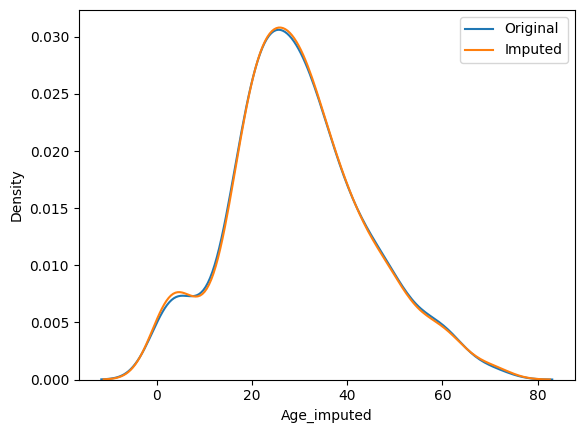

In [190]:
sns.distplot(X_train['Age'],label='Original',hist=False)
sns.distplot(X_train['Age_imputed'],label = 'Imputed',hist=False)

plt.legend()
plt.show()

In [191]:
print('Original variable variance: ', X_train['Age'].var())
print('Variance after random imputation: ', X_train['Age_imputed'].var())

Original variable variance:  204.3495133904614
Variance after random imputation:  206.44182955305104


In [192]:
X_train[['Fare', 'Age', 'Age_imputed']].cov()

,Fare,Age,Age_imputed
Fare,2368.246832,71.512440,64.039237
Age,71.512440,204.349513,204.349513
Age_imputed,64.039237,204.349513,206.441830


<Axes: >

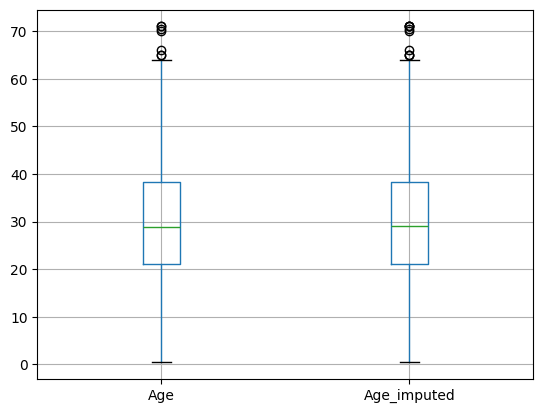

In [193]:
X_train[['Age', 'Age_imputed']].boxplot()

In [194]:
# production related
sampled_value = X_train['Age'].dropna().sample(1, random_state=int(observation['Fare']))

NameError: name 'observation' is not defined

In [196]:
data = pd.read_csv('https://raw.githubusercontent.com/campusx-official/100-days-of-machine-learning/main/day38-missing-indicator/house-train.csv',usecols=['GarageQual','FireplaceQu', 'SalePrice'])

In [197]:
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [198]:
data.isnull().mean() * 100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [199]:
X = data
y = data['SalePrice']

In [200]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [201]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

In [ ]:
X_train.sample(5)

In [202]:
X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_train['GarageQual'].isnull().sum()).values
X_test['GarageQual_imputed'][X_test['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_test['GarageQual'].isnull().sum()).values

X_train['FireplaceQu_imputed'][X_train['FireplaceQu_imputed'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu'].isnull().sum()).values
X_test['FireplaceQu_imputed'][X_test['FireplaceQu_imputed'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_test['FireplaceQu'].isnull().sum()).values

In [203]:
temp = pd.concat(
        [
            X_train['GarageQual'].value_counts() / len(X_train['GarageQual'].dropna()),
            X_train['GarageQual_imputed'].value_counts() / len(X_train)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

In [204]:
temp

,original,imputed
TA,0.951043,0.950342
Fa,0.037171,0.037671
Gd,0.009973,0.010274
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [205]:
temp = pd.concat(
        [
            X_train['FireplaceQu'].value_counts() / len(X_train['FireplaceQu'].dropna()),
            X_train['FireplaceQu_imputed'].value_counts() / len(df)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

temp

,original,imputed
Gd,0.494272,0.650954
TA,0.412439,0.540965
Fa,0.040917,0.050505
Po,0.027823,0.035915
Ex,0.024550,0.032548


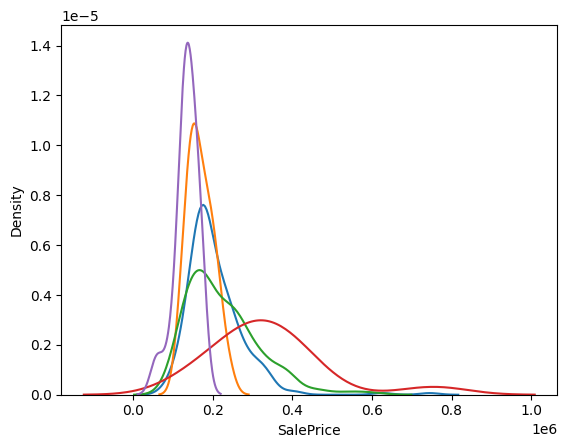

In [206]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.distplot(X_train[X_train['FireplaceQu'] == category]['SalePrice'],hist=False,label=category)
plt.show()

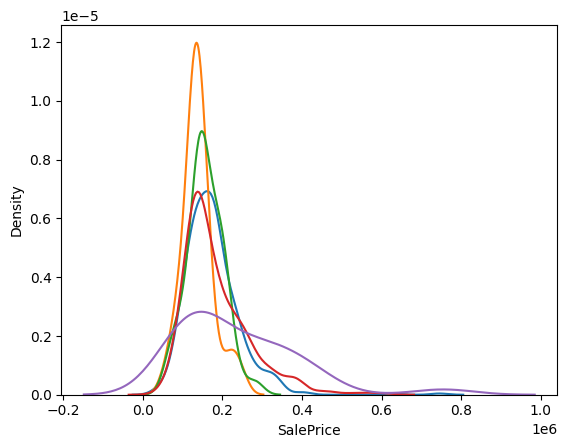

In [207]:
for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.distplot(X_train[X_train['FireplaceQu_imputed'] == category]['SalePrice'],hist=False,label=category)
plt.show()